# 03 – Models: does a larger NER model help?

Notebooks 01 and 02 use spaCy `nl_core_news_md`, the model of the current service. Two findings point at the model
itself: it gives every name the fixed score 0.85 (so thresholds cannot help), and it only looks a few words around
each token (so short labels get the wrong type, and a story does not help). The improvement overview expected a
larger model to help "only marginally, if at all", unless paired with more context.

This notebook tests two kinds of "larger" next to the current model (`improved.NER_MODELS`):

| Model | What it is |
|---|---|
| md | spaCy `nl_core_news_md` (current) |
| lg | spaCy `nl_core_news_lg`: the same architecture with larger word vectors |
| transformer | BERTje fine-tuned for Dutch NER (`wietsedv/bert-base-dutch-cased-finetuned-conll2002-ner`), via Presidio's `TransformersNlpEngine`: reads whole sentences and gives real confidence scores |

Only the NER model changes; the pattern recognizers (email, IBAN, rijksregisternummer, Belgian recognizers, …) are the
same. Everything runs on CPU.

## Setup

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import transformers

import experiment
import improved
import pii_eval

transformers.logging.set_verbosity_error()  # no model-loading warnings in the output
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 100)

files, elements, spans = pii_eval.load_corpus("data/synthetic")
STEPS = improved.cumulative_steps()
FORMATS = improved.INPUT_FORMATS
MODELS = list(improved.NER_MODELS)
LAST = list(STEPS)[-1]
for model in MODELS:
    improved.nlp_engine(model)  # load all models up front (downloads the transformer on first use)
print(f"{len(files)} files, {len(spans)} PII spans; models: {', '.join(MODELS)}")

/home/martijnbogaert/lblod/oph/presidio-bpmn-tryout/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


20 files, 205 PII spans; models: md, lg, transformer


### Configuring the transformer

BERTje splits words into word pieces ("Huysmans" → "Huys" + "##mans") and labels each piece. How the pieces are
combined into words matters a lot: with Presidio's default (`"max"`), the last part of many names is lost. The raw
Hugging Face output for two examples, per aggregation strategy:

In [2]:
hf = {}
for strategy in ["none", "max", "average", "simple", "first"]:
    pipe = transformers.pipeline("token-classification", model=improved.TRANSFORMER_NER, aggregation_strategy=strategy)
    for text in ["Annelies Huysmans", "Aanvrager Nele Vandenberghe, wonende te Gent."]:
        hf[strategy, text] = "; ".join(f"{o.get('entity_group') or o.get('entity')}: {o['word']}" for o in pipe(text))
pd.Series(hf).unstack()

,"Aanvrager Nele Vandenberghe, wonende te Gent.",Annelies Huysmans
average,loc: Gent,per: Annelies
first,per: Nele Vandenberghe; loc: Gent,per: Annelies Huysmans
max,loc: Gent,per: Annelies
none,B-per: Nel; I-per: Vandenbergh; B-loc: Gent,B-per: Annelies; I-per: Huys
simple,per: Nel; per: Vandenbergh; loc: Gent,per: Annelies Huys


Only `"first"` (a word gets the label of its first piece) gives the full names, so that is the configuration in
`improved.NER_MODELS`. With `"max"`, a first run of this notebook covered only 84% of the PII fully, against 98% for
md.

## Steps 0–11 per model (per element)

The improvement steps of notebook 01, with each element analyzed on its own, for every model.

In [3]:
runs = {}  # (model, input format, step) -> experiment.StepResult
for model in MODELS:
    for name, cfg in STEPS.items():
        runs[model, "per element", name] = experiment.run_step(replace(cfg, ner_model=model), files, spans)

def rows_for(keys):
    return pd.DataFrame([{"ner_model": m, "input_format": f, "step": s, **runs[m, f, s].row} for m, f, s in keys])

per_step = rows_for([(m, "per element", s) for m in MODELS for s in STEPS])
print(len(per_step), "runs")

36 runs


Check: md gives the same numbers as notebook 01 (`results/steps.csv`).

In [4]:
steps_csv = Path("results/steps.csv")
if steps_csv.exists():
    checked = ["precision", "recall", "recall_full", "recall_typed", "residual_pii"]
    nb01 = pd.read_csv(steps_csv).query("group == 'overall'").set_index("approach")
    ours = per_step[per_step.ner_model == "md"].set_index("step")
    pd.testing.assert_frame_equal(ours.loc[nb01.index, checked], nb01[checked], check_names=False)
    print(f"md == notebook 01 for {len(nb01)} steps")
else:
    print("run 01_improvements.ipynb first to compare with its results")

md == notebook 01 for 12 steps


In [5]:
METRICS = {
    "precision": "precision",
    "recall_full": "PII fully covered",
    "residual_pii": "PII left after anonymizing",
    "review_false_positives": "review items that are not PII",
}
table = per_step.pivot(index="step", columns="ner_model", values=list(METRICS)).loc[list(STEPS)]
table = table.reindex(columns=pd.MultiIndex.from_product([list(METRICS), MODELS]))
table.round(3)

precision                    recall_full         \
                                     md     lg transformer          md     lg   
step                                                                            
0 baseline                        0.622  0.708       0.495       0.385  0.429   
1 entity filter                   0.623  0.691       0.743       0.346  0.346   
2 thresholds                      0.655  0.715       0.767       0.405  0.405   
3 allow-list                      0.727  0.739       0.780       0.405  0.405   
4 RRN checksum                    0.727  0.739       0.780       0.410  0.410   
5 acronym gate                    0.727  0.739       0.800       0.410  0.410   
6 dedup                           0.727  0.739       0.800       0.410  0.410   
7 documentation + annotations     0.801  0.814       0.832       0.727  0.741   
8 Belgian recognizers             0.837  0.857       0.867       0.941  0.956   
9 no LOCATION                     0.954  0.990       0.975       0.941  0.956   
10 name particles                 0.953  0.990       0.975       0.976  0.961   
11 name parts                     0.953  0.990       0.975       0.976  0.961   

                                          residual_pii                     \
                              transformer           md     lg transformer   
step                                                                        
0 baseline                          0.371        0.600  0.571       0.610   
1 entity filter                     0.322        0.644  0.649       0.659   
2 thresholds                        0.376        0.585  0.590       0.605   
3 allow-list                        0.376        0.585  0.590       0.605   
4 RRN checksum                      0.380        0.585  0.590       0.605   
5 acronym gate                      0.380        0.585  0.590       0.605   
6 dedup                             0.380        0.585  0.590       0.605   
7 documentation + annotations       0.727        0.254  0.268       0.268   
8 Belgian recognizers               0.927        0.029  0.044       0.054   
9 no LOCATION                       0.941        0.029  0.044       0.044   
10 name particles                   0.946        0.024  0.034       0.044   
11 name parts                       0.946        0.015  0.020       0.005   

                              review_false_positives                    
                                                  md    lg transformer  
step                                                                    
0 baseline                                      62.0  42.0        94.0  
1 entity filter                                 49.0  34.0        28.0  
2 thresholds                                    49.0  35.0        28.0  
3 allow-list                                    35.0  31.0        26.0  
4 RRN checksum                                  35.0  31.0        26.0  
5 acronym gate                                  35.0  31.0        23.0  
6 dedup                                         34.0  31.0        23.0  
7 documentation + annotations                   44.0  39.0        36.0  
8 Belgian recognizers                           39.0  33.0        30.0  
9 no LOCATION                                    9.0   2.0         5.0  
10 name particles                                9.0   2.0         5.0  
11 name parts                                    9.0   2.0         5.0

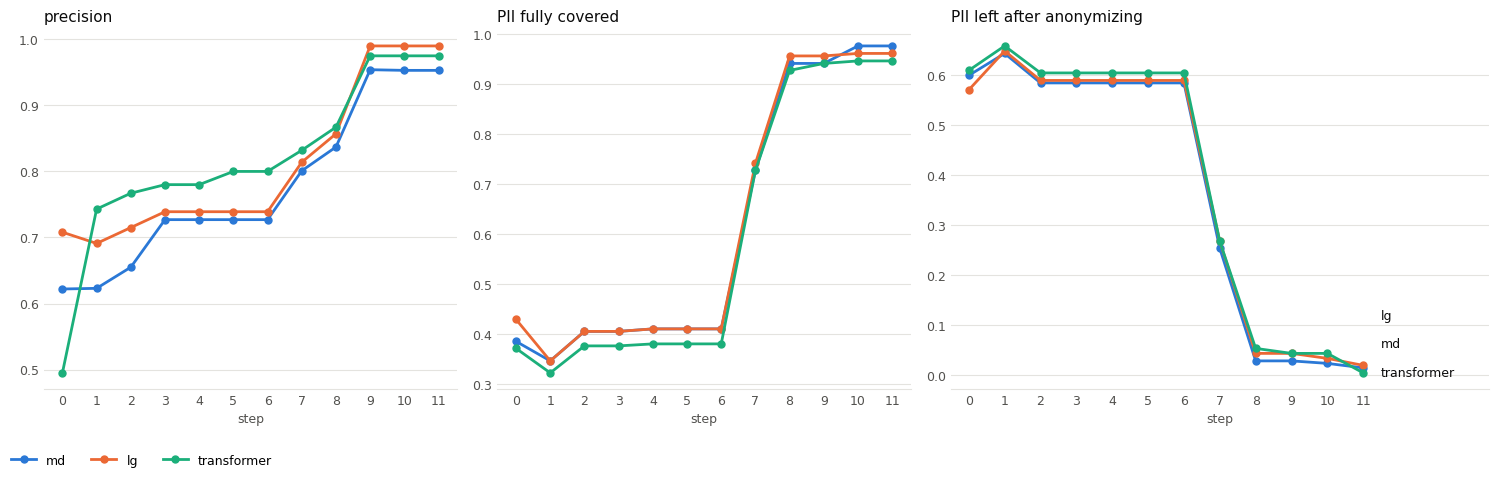

In [6]:
# Categorical slots 1-3 of the reference palette, one per model; values are also in the table above
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PANELS = ["precision", "recall_full", "residual_pii"]

x = range(len(STEPS))
short = [name.split(" ", 1)[0] for name in STEPS]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, metric in zip(axes, PANELS):
    for model, color in COLORS.items():
        ax.plot(x, table[metric][model], color=color, linewidth=2, marker="o", markersize=5, label=model)
    ax.set_title(METRICS[metric], loc="left", fontsize=11, color=INK)
    ax.set_xticks(list(x), short)
    ax.set_xlabel("step", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# direct labels at the line ends of the last panel, nudged apart when the values are close
ax, metric = axes[-1], PANELS[-1]
low, high = ax.get_ylim()
label_y, prev = {}, low - 1
for model in sorted(MODELS, key=lambda m: table[metric][m].iloc[-1]):
    prev = label_y[model] = max(table[metric][model].iloc[-1], prev + 0.08 * (high - low))
for model in MODELS:
    ax.annotate(model, (len(STEPS) - 1, table[metric][model].iloc[-1]), xytext=(len(STEPS) - 0.5, label_y[model]),
                textcoords="data", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.5, len(STEPS) + 2.5)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower left", frameon=False, fontsize=9, ncol=len(MODELS))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

### Scores

The thresholds of step 2 were chosen for spaCy, whose PERSON and LOCATION results always score 0.85. The scores of
PERSON and LOCATION detections at step 1 (before thresholds), per model:

In [7]:
bins = [0, 0.4, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0]
scores = pd.concat([
    runs[m, "per element", "1 entity filter"].detections.assign(ner_model=m) for m in MODELS
]).query("entity in ['PERSON', 'LOCATION']")
pd.crosstab([scores.ner_model, scores.entity], pd.cut(scores.score, bins, include_lowest=True))

score                 (0.7, 0.8]  (0.8, 0.85]  (0.85, 0.9]  (0.95, 1.0]
ner_model   entity                                                     
lg          LOCATION           0           36            0            0
            PERSON             0           53            0            0
md          LOCATION           0           40            0            0
            PERSON             0           69            0            0
transformer LOCATION           0            0            0           30
            PERSON             1            1            1           55

## All input formats at step 11, per model

Does a model that reads more context make one text per diagram, or the story, better than per element?

In [8]:
for model in MODELS:
    for fmt, switches in FORMATS.items():
        if (model, fmt, LAST) not in runs:
            runs[model, fmt, LAST] = experiment.run_step(replace(STEPS[LAST], ner_model=model, **switches), files, spans)

grid = rows_for([(m, f, LAST) for m in MODELS for f in FORMATS]).set_index(["ner_model", "input_format"])
grid.loc[:, [*METRICS, "detect_seconds"]].rename(columns=METRICS).round(3)

precision  PII fully covered  \
ner_model   input_format                                    
md          per element          0.953              0.976   
            one text             0.990              0.937   
            one text + type      0.980              0.956   
            flow order           0.980              0.956   
            story                0.961              0.951   
lg          per element          0.990              0.961   
            one text             1.000              0.956   
            one text + type      0.980              0.961   
            flow order           0.980              0.961   
            story                0.985              0.971   
transformer per element          0.975              0.946   
            one text             0.933              0.937   
            one text + type      0.930              0.946   
            flow order           0.900              0.946   
            story                0.929              0.932   

                             PII left after anonymizing  \
ner_model   input_format                                  
md          per element                           0.015   
            one text                              0.020   
            one text + type                       0.024   
            flow order                            0.024   
            story                                 0.024   
lg          per element                           0.020   
            one text                              0.020   
            one text + type                       0.024   
            flow order                            0.024   
            story                                 0.024   
transformer per element                           0.005   
            one text                              0.015   
            one text + type                       0.015   
            flow order                            0.010   
            story                                 0.015   

                             review items that are not PII  detect_seconds  
ner_model   input_format                                                    
md          per element                                  9            1.69  
            one text                                     2            1.05  
            one text + type                              4            0.57  
            flow order                                   4            0.54  
            story                                        8            0.71  
lg          per element                                  2            1.67  
            one text                                     0            1.00  
            one text + type                              4            0.55  
            flow order                                   4            0.53  
            story                                        3            0.67  
transformer per element                                  5           19.25  
            one text                                    14            5.32  
            one text + type                             15            6.91  
            flow order                                  20            6.66  
            story                                       15            7.69

Difference with md for the same input format (positive = higher than md):

In [9]:
cols = list(METRICS)
diff = pd.concat({m: grid.loc[m, cols] - grid.loc["md", cols] for m in MODELS if m != "md"})
diff.rename(columns=METRICS).round(3)

precision  PII fully covered  \
            input_format                                    
lg          per element          0.037             -0.015   
            one text             0.010              0.019   
            one text + type      0.000              0.005   
            flow order           0.000              0.005   
            story                0.024              0.020   
transformer per element          0.022             -0.030   
            one text            -0.057              0.000   
            one text + type     -0.050             -0.010   
            flow order          -0.080             -0.010   
            story               -0.032             -0.019   

                             PII left after anonymizing  \
            input_format                                  
lg          per element                           0.005   
            one text                              0.000   
            one text + type                       0.000   
            flow order                            0.000   
            story                                 0.000   
transformer per element                          -0.010   
            one text                             -0.005   
            one text + type                      -0.009   
            flow order                           -0.014   
            story                                -0.009   

                             review items that are not PII  
            input_format                                    
lg          per element                                 -7  
            one text                                    -2  
            one text + type                              0  
            flow order                                   0  
            story                                       -5  
transformer per element                                 -4  
            one text                                    12  
            one text + type                             11  
            flow order                                  16  
            story                                        7

## The four short labels

What each model makes of the four labels from notebook 02, analyzed on their own (per element) and inside the story.
Only PERSON counts as a name in the pipeline (the transformer's labels are `per`, `loc`, `org`, `misc`).

In [10]:
labels = {
    "melding-openbaar-domein-hasselt.bpmn": "Tom - Burgerzaken",
    "aanvraag-rijbewijs-tienen.bpmn": "Contact Marleen (+32493276528)",
    "subsidie-vereniging-aalst.bpmn": "Dossier Marleen Jacobs (°04/03/1996)",
    "huwelijk-genk.bpmn": "Doorsturen naar Lander Yilmaz",
}
found = {}
for model in MODELS:
    nlp = improved.spacy_model("nl", model)
    for fmt in ["per element", "story"]:
        for f, label in labels.items():
            if fmt == "per element":
                text, start = label, 0
            else:
                text, _ = improved.bpmn_document(files[f], replace(STEPS[LAST], **FORMATS[fmt]))
                start = text.index(label)
            ents = [f"{t} → {lab}" for t, lab, s, e in improved.ner_entities(nlp(text)) if start <= s and e <= start + len(label)]
            found[label, (model, fmt)] = "; ".join(ents) or "–"
pd.Series(found).unstack()

,"(lg, per element)","(lg, story)","(md, per element)","(md, story)","(transformer, per element)","(transformer, story)"
Contact Marleen (+32493276528),+32493276528 → DATE,+32493276528 → DATE,Marleen → PERSON; +32493276528 → DATE,Contact Marleen → WORK_OF_ART; +32493276528 → DATE,Marleen → org,Contact Marleen → org
Doorsturen naar Lander Yilmaz,Lander Yilmaz → PERSON,Lander Yilmaz → PERSON,–,Yilmaz → PERSON,Lander Yilmaz → per,Lander Yilmaz → per
Dossier Marleen Jacobs (°04/03/1996),Marleen Jacobs → PERSON; 04/03/1996 → DATE,Marleen Jacobs → PERSON; 04/03/1996 → DATE,Marleen Jacobs → PERSON; 04/03/1996 → DATE,Dossier Marleen Jacobs → WORK_OF_ART,Marleen Jacobs → per,Marleen Jacobs → per
Tom - Burgerzaken,Tom → PERSON,Tom → PERSON,Tom - Burgerzaken → PERSON,Tom - Burgerzaken → WORK_OF_ART,Tom → per,Tom → per


## The best transformer configuration compared with md per element (step 11)

In [11]:
f1 = lambda r: 2 * r.precision * r.recall_full / (r.precision + r.recall_full)
best_fmt = str(grid.loc["transformer"].apply(f1, axis=1).idxmax())
print("best input format for the transformer (F1 of precision and PII fully covered):", best_fmt)
ref, best = runs["md", "per element", LAST], runs["transformer", best_fmt, LAST]
d = pii_eval.diff_steps((ref.spans, ref.detections), (best.spans, best.detections))
for title in ["pii_gained", "pii_lost", "fp_removed", "fp_added"]:
    print(f"\n--- {title}: {len(d[title])}")
    if len(d[title]):
        display(d[title])

best input format for the transformer (F1 of precision and PII fully covered): per element

--- pii_gained: 2


,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz
178,leefloon-turnhout.bpmn,name,PERSON,Annelies,Annelies - Burgerzaken



--- pii_lost: 8


,file,location,entity,value,text
3,aanvraag-rijbewijs-sintniklaas.bpmn,name,PERSON,Marleen,Marleen - Burgerzaken
25,omgevingsvergunning-poperinge.bpmn,name,PERSON,Fien,Fien - Burgerzaken
76,melding-openbaar-domein-roeselare.bpmn,name,PERSON,Marleen,Marleen - Burgerzaken
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
150,bewonerskaart-sintniklaas.bpmn,name,PERSON,Nathalie,Contact Nathalie (03 633 19 41)
156,bewonerskaart-sintniklaas.bpmn,name,PERSON,Janssens,Goedkeuring door dhr. Janssens
162,subsidie-vereniging-aalter.bpmn,name,PERSON,Mohamed,Mohamed - Burgerzaken
192,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Inge,Contact Inge (+32 11 93 64 26)



--- fp_removed: 10


,location,entity,match
1,name,PERSON,Woonstvaststelling
2,name,PERSON,Plaatsbezoek
4,documentation,PERSON,Opgelet
5,name,PERSON,Plaatsbezoek
6,name,PERSON,Mobiliteitsambtenaar
7,name,PERSON,OMV_2022098043
10,name,PERSON,Adviezen
11,name,PERSON,Adviezen
13,name,PERSON,Adviezen
14,documentation,PERSON,Opgelet



--- fp_added: 5


,location,entity,match
0,text,PERSON,Ambtenaar
1,name,PERSON,SharePoint
2,text,PERSON,Ambtenaar
3,name,PERSON,SharePoint
4,text,PERSON,Ambtenaar


In [12]:
s, det = best.spans, best.detections
print("PII not fully covered:")
display(s.loc[~s.full, ["location", "entity", "value", "text"]])
print("false positives:")
det.loc[~det.tp].merge(elements[[*pii_eval.KEY, "text"]], on=pii_eval.KEY)[["location", "entity", "match", "score", "text"]]

PII not fully covered:


,location,entity,value,text
3,name,PERSON,Marleen,Marleen - Burgerzaken
25,name,PERSON,Fien,Fien - Burgerzaken
35,name,PERSON,Ann-Sophie Mertens,Doorsturen naar Ann-Sophie Mertens
76,name,PERSON,Marleen,Marleen - Burgerzaken
93,name,PERSON,Marleen,Contact Marleen (+32493276528)
131,name,PERSON,Jean-Pierre Huysmans,Advies vragen aan Jean-Pierre Huysmans
137,name,PERSON,Lander,Lander - Burgerzaken
150,name,PERSON,Nathalie,Contact Nathalie (03 633 19 41)
156,name,PERSON,Janssens,Goedkeuring door dhr. Janssens
162,name,PERSON,Mohamed,Mohamed - Burgerzaken


false positives:


,location,entity,match,score,text
0,text,PERSON,Ambtenaar,0.949,Te bespreken met Ambtenaar van de burgerlijke stand
1,name,PERSON,SharePoint,1.000,SharePoint
2,text,PERSON,Ambtenaar,0.949,Te bespreken met Ambtenaar van de burgerlijke stand
3,name,PERSON,SharePoint,1.000,SharePoint
4,text,PERSON,Ambtenaar,0.949,Te bespreken met Ambtenaar van de burgerlijke stand


## Cost

In [13]:
import spacy
from huggingface_hub import scan_cache_dir


def size_mb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 1e6


hf_cache = {repo.repo_id: repo.size_on_disk / 1e6 for repo in scan_cache_dir().repos}
model_size = {
    "md": size_mb(spacy.util.get_package_path("nl_core_news_md")),
    "lg": size_mb(spacy.util.get_package_path("nl_core_news_lg")),
    "transformer": size_mb(spacy.util.get_package_path("nl_core_news_md")) + hf_cache.get(improved.TRANSFORMER_NER, 0),
}
cost = pd.DataFrame(grid["detect_seconds"].unstack("input_format")).loc[:, list(FORMATS)]
cost.insert(0, "model size (MB)", pd.Series(model_size).round())
cost

input_format,model size (MB),per element,one text,one text + type,flow order,story
ner_model,,,,,,
lg,631.0,1.67,1.00,0.55,0.53,0.67
md,55.0,1.69,1.05,0.57,0.54,0.71
transformer,491.0,19.25,5.32,6.91,6.66,7.69


Detection time in seconds for all 20 diagrams (models already loaded), per input format.

In [14]:
out = pd.concat([r.summary.assign(ner_model=m, input_format=f) for (m, f, s), r in runs.items()])
out = out[["ner_model", "input_format", *experiment.SUMMARY_COLUMNS]]
Path("results").mkdir(exist_ok=True)
out.to_csv("results/models.csv", index=False)
print(f"{len(out)} rows -> results/models.csv")

624 rows -> results/models.csv


## Conclusions

At step 11 (all improvements), the most relevant combinations:

| Model | Input format | Precision | PII fully covered | PII left after anonymizing | Not-PII on review list | Detection time (20 diagrams) |
|---|---|---|---|---|---|---|
| md | per element | 0.953 | 0.976 | 1.5% | 9 | ≈1.7 s |
| lg | per element | 0.990 | 0.961 | 2.0% | 2 | ≈1.8 s |
| lg | one text | 1.000 | 0.956 | 2.0% | 0 | ≈0.45 s |
| lg | story | 0.985 | 0.971 | 2.4% | 3 | ≈0.7 s |
| transformer | per element | 0.975 | 0.946 | **0.5%** | 5 | ≈19 s |
| transformer | one text + type | 0.930 | 0.946 | 1.5% | 15 | ≈6.7 s |

**Size (lg) helps more than expected, mainly for precision.** Same architecture and speed as md, but far fewer
capitalized nouns taken for names (2 false positives instead of 9 per element, none in one text). It also labels short
names as PERSON where md said ORG or WORK_OF_ART ("Tom - Burgerzaken", "Doorsturen naar Lander Yilmaz"), so with lg
the story is the best one-text format (97.1% fully covered). Per element it covers slightly less than md (96.1% vs.
97.6%). Cost: 631 MB instead of 55 MB, no extra time.

**The transformer leaks the least, at a cost.** Per element it leaves only 0.5% of the PII after anonymizing: it finds
names md misses ("Lander Yilmaz", "Annelies - Burgerzaken") and its full names make the name-part masking of step 11
very effective. But detection is about 10× slower on CPU (≈1 s per diagram), it needs torch and ~0.5 GB of model, and
it only works well with the right configuration: with Presidio's default aggregation (`"max"`) it lost the last part
of most names (84% fully covered instead of 95%).

**A transformer does not make one text per diagram better.** In one text it takes lane and role names ("Burger",
"Brandweer", "Melder") and titles ("dhr.") for persons: 15 not-PII items instead of 5.

**Thresholds still do not matter.** The transformer gives real scores, but nearly all of them are above 0.95, so the
step-2 thresholds change nothing for any model.

**Which to choose depends on the priority**
- Least PII left behind: **transformer, per element**, if ≈1 s per diagram on CPU (or a GPU) is acceptable.
- Cleanest review list and cheapest: **lg, one text** (no false positives, one call per diagram, 2.0% left).
- md per element (the current model) remains a reasonable middle ground.

These are results on a small synthetic corpus with a limited list of first and last names; real OPH diagrams are
needed before choosing.